## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 04 — Otimização da Alocação de Orçamento (Limite de R$ 10 Milhões)

**Objetivo:** Selecionar o portfólio ótimo de praças e alavancas respeitando integralmente as restrições do case:
1. **Orçamento máximo de R$ 10,0 milhões** (`sum(custo_alavanca_m) <= 10.0`), garantindo que o investimento/impacto negativo bruto não ultrapasse o teto financeiro.
2. **No máximo 1 alavanca por cidade** (sem sobreposição de incentivos na mesma praça).
3. **Bloqueio de estímulo bruto de demanda em praças saturadas (`saturacao_base_pct > 100%`)**, permitindo apenas ações de capacidade logística.
4. **Solução exata via Programação Linear Inteira Mista (`scipy.optimize.milp`)**, maximizando o retorno combinado de **GMV Incremental e Margem de Contribuição** dentro do teto de R$ 10M.


In [3]:
import os
import numpy as np
import pandas as pd
from scipy.optimize import milp, LinearConstraint, Bounds
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = ".." if os.path.exists("../data/processed/base_impacto.csv") else ("." if os.path.exists("data/processed/base_impacto.csv") else "/content")
IMPACT_PATH = os.path.join(BASE_DIR, "data", "processed", "base_impacto.csv")
OPTIMIZED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_alocacao_otimizada.csv")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

TOTAL_BUDGET_M = 10.0

impact_df = pd.read_csv(IMPACT_PATH)

candidates = impact_df[
    (impact_df["viavel_operacionalmente"]) &
    (impact_df["custo_alavanca_m"] > 0) &
    (impact_df["custo_alavanca_m"] <= TOTAL_BUDGET_M) &
    (impact_df["gmv_incremental_m"] > 0)
].reset_index(drop=True)

print("Candidatos elegíveis dentro do teto de R$ 10M:", len(candidates))
display(candidates[[
    "cidade", "arquetipo_operacional", "alavanca", "custo_alavanca_m",
    "gmv_incremental_m", "margem_contribuicao_incremental_m",
    "operating_margin_incremental_m", "roi_gmv"
]])


Candidatos elegíveis dentro do teto de R$ 10M: 13


,cidade,arquetipo_operacional,alavanca,custo_alavanca_m,gmv_incremental_m,margem_contribuicao_incremental_m,operating_margin_incremental_m,roi_gmv
0,City 17,Destravamento de Capacidade (Saturada),Incentivos para Entregadores,4.9977,6.2200,0.4590,-4.5387,1.24
1,City 18,Turnaround Estrutural,Incentivos para Clientes,0.2815,2.6722,0.2063,-0.0752,9.49
2,City 18,Turnaround Estrutural,Frete Grátis,0.3565,2.7078,0.2090,-0.1475,7.60
3,City 18,Turnaround Estrutural,Alterações de Preço,0.5222,1.6033,0.1238,-0.3985,3.07
4,City 2,Ataque Competitivo,Incentivos para Clientes,0.3869,5.5956,0.5014,0.1145,14.46
5,City 2,Ataque Competitivo,Frete Grátis,0.4900,5.6702,0.5080,0.0180,11.57
6,City 2,Ataque Competitivo,Alterações de Preço,1.1177,5.3717,0.4813,-0.6364,4.81
7,City 3,Ataque Competitivo,Incentivos para Clientes,0.5885,6.4520,0.5304,-0.0582,10.96
8,City 3,Ataque Competitivo,Frete Grátis,0.9784,8.5812,0.7054,-0.2731,8.77
9,City 3,Ataque Competitivo,Alterações de Preço,1.2888,6.1939,0.5091,-0.7797,4.81


## 1. Otimização Exata via MILP (`scipy.optimize.milp`)


In [4]:
n = len(candidates)
if n == 0:
    raise ValueError("Nenhuma combinação elegível encontrada dentro do orçamento.")

# Função objetivo: maximizar criação de valor (GMV incremental + 3x Margem de Contribuição incremental)
score_valor = candidates["gmv_incremental_m"].values + 3.0 * candidates["margem_contribuicao_incremental_m"].values
c = -score_valor

integrality = np.ones(n)
bounds = Bounds(lb=np.zeros(n), ub=np.ones(n))

constraints = []

# Restrição 1: Orçamento total <= R$ 10.0M
A_budget = candidates["custo_alavanca_m"].values.reshape(1, -1)
constraints.append(LinearConstraint(A_budget, -np.inf, TOTAL_BUDGET_M))

# Restrição 2: No máximo 1 alavanca por cidade
for city in candidates["cidade"].unique():
    row_mask = (candidates["cidade"] == city).astype(float).values.reshape(1, -1)
    constraints.append(LinearConstraint(row_mask, -np.inf, 1.0))

res = milp(c=c, integrality=integrality, bounds=bounds, constraints=constraints)
if not res.success:
    raise RuntimeError(f"Falha na otimização: {res.message}")

candidates["selecionada"] = np.round(res.x).astype(int)
allocation_df = candidates[candidates["selecionada"] == 1].copy()
allocation_df = allocation_df.sort_values("gmv_incremental_m", ascending=False).reset_index(drop=True)
allocation_df["investimento_alocado_m"] = allocation_df["custo_alavanca_m"]

display(allocation_df[[
    "cidade", "arquetipo_operacional", "alavanca",
    "investimento_alocado_m", "pedidos_incrementais_k",
    "gmv_incremental_m", "margem_contribuicao_incremental_m",
    "operating_margin_incremental_m", "saturacao_base_pct", "saturacao_pos_pct", "roi_gmv"
]])


,cidade,arquetipo_operacional,alavanca,investimento_alocado_m,pedidos_incrementais_k,gmv_incremental_m,margem_contribuicao_incremental_m,operating_margin_incremental_m,saturacao_base_pct,saturacao_pos_pct,roi_gmv
0,City 3,Ataque Competitivo,Frete Grátis,0.9784,111.8213,8.5812,0.7054,-0.2731,79.81,85.75,8.77
1,City 17,Destravamento de Capacidade (Saturada),Incentivos para Entregadores,4.9977,76.6296,6.2200,0.4590,-4.5387,131.38,119.38,1.24
2,City 2,Ataque Competitivo,Incentivos para Clientes,0.3869,77.3722,5.5956,0.5014,0.1145,83.86,88.00,14.46
3,City 18,Turnaround Estrutural,Frete Grátis,0.3565,40.7436,2.7078,0.2090,-0.1475,78.48,83.00,7.60
4,City 6,Ataque Focalizado (Alerta Capacidade),Incentivos para Entregadores,2.0727,34.1952,2.4217,0.1896,-1.8831,96.50,84.50,1.17
5,City 4,Destravamento de Capacidade (Saturada),Incentivos para Entregadores,1.1871,30.3458,1.9952,0.1552,-1.0319,129.05,117.05,1.68


## 2. Resumo Consolidado do Portfólio Otimizado


In [5]:
total_investment = allocation_df["investimento_alocado_m"].sum()
total_orders = allocation_df["pedidos_incrementais_k"].sum()
total_gmv = allocation_df["gmv_incremental_m"].sum()
total_mc = allocation_df["margem_contribuicao_incremental_m"].sum()
total_op_margin = allocation_df["operating_margin_incremental_m"].sum()

print(f"Praças selecionadas: {len(allocation_df)}")
print(f"Investimento total alocado: R$ {total_investment:.2f}M (Limite máximo: R$ {TOTAL_BUDGET_M:.2f}M)")
print(f"Folga de orçamento: R$ {TOTAL_BUDGET_M - total_investment:.2f}M")
print(f"Pedidos incrementais (12m): {total_orders:,.1f} mil")
print(f"GMV incremental (12m): R$ {total_gmv:.2f}M")
print(f"Margem de Contribuição incremental: R$ {total_mc:.2f}M")
print(f"Impacto líquido na Operating Margin (MC inc. - Investimento): R$ {total_op_margin:.2f}M")
print(f"ROI GMV do portfólio: {total_gmv / total_investment:.2f}x")


Praças selecionadas: 6
Investimento total alocado: R$ 9.98M (Limite máximo: R$ 10.00M)
Folga de orçamento: R$ 0.02M
Pedidos incrementais (12m): 371.1 mil
GMV incremental (12m): R$ 27.52M
Margem de Contribuição incremental: R$ 2.22M
Impacto líquido na Operating Margin (MC inc. - Investimento): R$ -7.76M
ROI GMV do portfólio: 2.76x


## 3. Visualização da Alocação Final


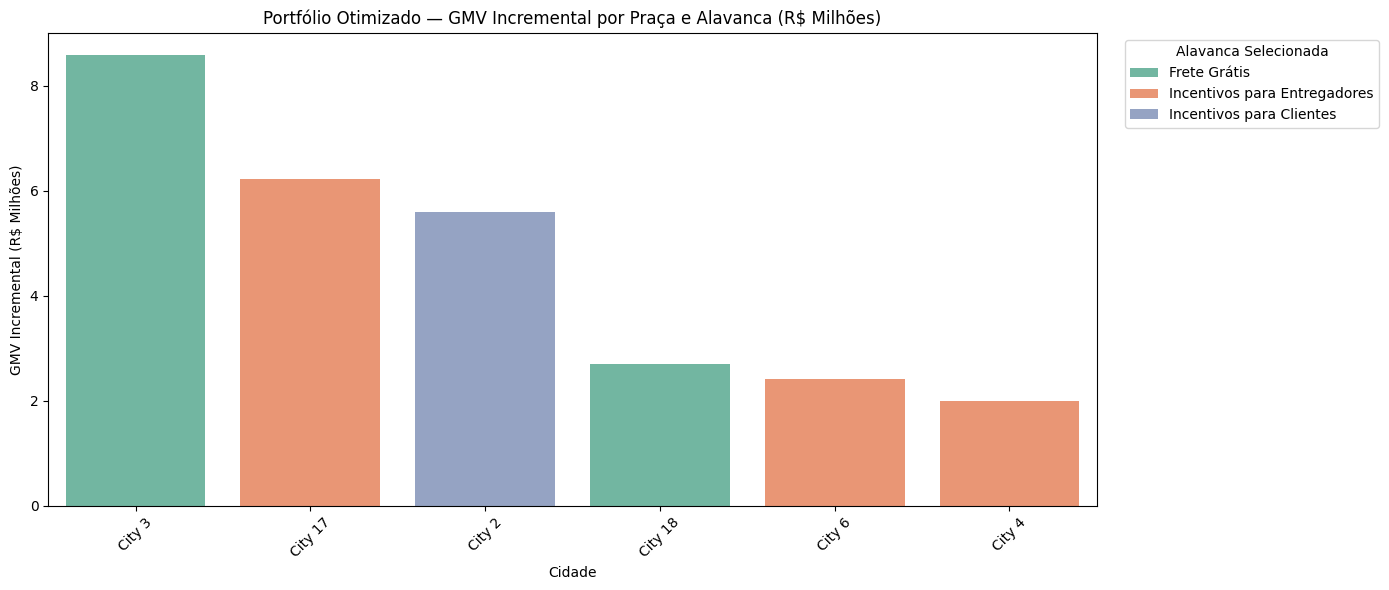

In [6]:
plt.figure(figsize=(14, 6))
sns.barplot(
    data=allocation_df,
    x="cidade",
    y="gmv_incremental_m",
    hue="alavanca",
    palette="Set2"
)
plt.title("Portfólio Otimizado — GMV Incremental por Praça e Alavanca (R$ Milhões)")
plt.xlabel("Cidade")
plt.ylabel("GMV Incremental (R$ Milhões)")
plt.xticks(rotation=45)
plt.legend(title="Alavanca Selecionada", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_alocacao_final.png"), bbox_inches="tight", dpi=150)
plt.show()


## 4. Exportação da Alocação Otimizada


In [7]:
allocation_df.to_csv(OPTIMIZED_PATH, index=False)
print("Alocação otimizada salva em:", OPTIMIZED_PATH)


Alocação otimizada salva em: ./data/processed/base_alocacao_otimizada.csv
